In [1]:
import pandas as pd
import pyarrow

print("Pandas:", pd.__version__)
print("PyArrow:", pyarrow.__version__)

Pandas: 2.2.3
PyArrow: 23.0.1


In [2]:
url = "https://raw.githubusercontent.com/Alirafe/black_friday_iran_analysis/main/data/cpi_sci.parquet"

df_cpi = pd.read_parquet(url)

print("ابعاد داده:", df_cpi.shape)
display(df_cpi.head())

ابعاد داده: (183, 11)


,source_id,freq,period,year,month,base_year,cpi_index,inflation_annual,inflation_yoy,inflation_mom,vintage
0,sci,M,1390-01,1390,1.0,1400,10.855119,NaN,NaN,NaN,1405-03
1,sci,M,1390-02,1390,2.0,1400,11.154133,NaN,NaN,2.754588,1405-03
2,sci,M,1390-03,1390,3.0,1400,11.353604,NaN,NaN,1.788313,1405-03
3,sci,M,1390-04,1390,4.0,1400,11.563497,NaN,NaN,1.848689,1405-03
4,sci,M,1390-05,1390,5.0,1400,11.823574,NaN,NaN,2.249122,1405-03


In [3]:
print("ابعاد دیتاست:")
print(df_cpi.shape)

print("\nنام ستون‌ها:")
print(df_cpi.columns.tolist())

print("\nنوع داده‌های هر ستون:")
print(df_cpi.dtypes)

print("\nتعداد مقادیر خالی:")
print(df_cpi.isnull().sum())

print("\nپنج ردیف آخر:")
display(df_cpi.tail())

ابعاد دیتاست:
(183, 11)

نام ستون‌ها:
['source_id', 'freq', 'period', 'year', 'month', 'base_year', 'cpi_index', 'inflation_annual', 'inflation_yoy', 'inflation_mom', 'vintage']

نوع داده‌های هر ستون:
source_id            object
freq                 object
period               object
year                  int64
month               float64
base_year             int64
cpi_index           float64
inflation_annual    float64
inflation_yoy       float64
inflation_mom       float64
vintage              object
dtype: object

تعداد مقادیر خالی:
source_id            0
freq                 0
period               0
year                 0
month                0
base_year            0
cpi_index            0
inflation_annual    24
inflation_yoy       12
inflation_mom        1
vintage              0
dtype: int64

پنج ردیف آخر:


,source_id,freq,period,year,month,base_year,cpi_index,inflation_annual,inflation_yoy,inflation_mom,vintage
178,sci,M,1404-11,1404,11.0,1400,513.637392,47.530447,68.117385,9.432659,1405-03
179,sci,M,1404-12,1404,12.0,1400,542.341434,50.616097,71.794934,5.588386,1405-03
180,sci,M,1405-01,1405,1.0,1400,569.328804,53.686516,73.515170,4.976085,1405-03
181,sci,M,1405-02,1405,2.0,1400,619.574077,57.698993,83.892085,8.825352,1405-03
182,sci,M,1405-03,1405,3.0,1400,656.369579,62.022827,88.580200,5.938838,1405-03


In [4]:
for col in ['inflation_annual', 'inflation_yoy', 'inflation_mom']:

    print("\nمتغیر:", col)

    missing = df_cpi[df_cpi[col].isna()]

    print("تعداد مقادیر خالی:", len(missing))
    print("اولین دوره خالی:", missing['period'].min())
    print("آخرین دوره خالی:", missing['period'].max())

    display(missing[['period', 'year', 'month']].head(5))



متغیر: inflation_annual
تعداد مقادیر خالی: 24
اولین دوره خالی: 1390-01
آخرین دوره خالی: 1391-12


,period,year,month
0,1390-01,1390,1.0
1,1390-02,1390,2.0
2,1390-03,1390,3.0
3,1390-04,1390,4.0
4,1390-05,1390,5.0



متغیر: inflation_yoy
تعداد مقادیر خالی: 12
اولین دوره خالی: 1390-01
آخرین دوره خالی: 1390-12


,period,year,month
0,1390-01,1390,1.0
1,1390-02,1390,2.0
2,1390-03,1390,3.0
3,1390-04,1390,4.0
4,1390-05,1390,5.0



متغیر: inflation_mom
تعداد مقادیر خالی: 1
اولین دوره خالی: 1390-01
آخرین دوره خالی: 1390-01


,period,year,month
0,1390-01,1390,1.0


In [5]:
print("تعداد دوره‌های یکتا:", df_cpi['period'].nunique())

print("تعداد دوره‌های تکراری:",
      df_cpi['period'].duplicated().sum())

print("\nتعداد ماه‌های ثبت‌شده در هر سال:")
display(df_cpi.groupby('year')['month'].count())

print("\nبررسی ترتیب زمانی:")
display(df_cpi[['period', 'cpi_index']].head(3))
display(df_cpi[['period', 'cpi_index']].tail(3))

تعداد دوره‌های یکتا: 183
تعداد دوره‌های تکراری: 0

تعداد ماه‌های ثبت‌شده در هر سال:


,month
year,
1390,12
1391,12
1392,12
1393,12
1394,12
1395,12
1396,12
1397,12
1398,12



بررسی ترتیب زمانی:


,period,cpi_index
0,1390-01,10.855119
1,1390-02,11.154133
2,1390-03,11.353604


,period,cpi_index
180,1405-01,569.328804
181,1405-02,619.574077
182,1405-03,656.369579


In [6]:
!pip install jdatetime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jdatetime]


In [7]:
import jdatetime
import pandas as pd

# تبدیل تاریخ شروع هر ماه شمسی به میلادی
df_cpi['gregorian_date'] = df_cpi['period'].apply(
    lambda x: pd.Timestamp(
        jdatetime.date(
            int(x.split('-')[0]),
            int(x.split('-')[1]),
            1
        ).togregorian()
    )
)

# استخراج سال و ماه میلادی
df_cpi['gregorian_year'] = df_cpi['gregorian_date'].dt.year
df_cpi['gregorian_month'] = df_cpi['gregorian_date'].dt.month

# ساخت شناسه ماه میلادی
df_cpi['gregorian_period'] = (
    df_cpi['gregorian_date'].dt.strftime('%Y-%m')
)

display(
    df_cpi[
        ['period', 'gregorian_date',
         'gregorian_year', 'gregorian_month',
         'gregorian_period']
    ].head(15)
)

,period,gregorian_date,gregorian_year,gregorian_month,gregorian_period
0,1390-01,2011-03-21,2011,3,2011-03
1,1390-02,2011-04-21,2011,4,2011-04
2,1390-03,2011-05-22,2011,5,2011-05
3,1390-04,2011-06-22,2011,6,2011-06
4,1390-05,2011-07-23,2011,7,2011-07
5,1390-06,2011-08-23,2011,8,2011-08
6,1390-07,2011-09-23,2011,9,2011-09
7,1390-08,2011-10-23,2011,10,2011-10
8,1390-09,2011-11-22,2011,11,2011-11
9,1390-10,2011-12-22,2011,12,2011-12


In [8]:
import jdatetime
import pandas as pd

def jalali_month_end(period):
    year, month = map(int, period.split('-'))

    if month == 12:
        next_year, next_month = year + 1, 1
    else:
        next_year, next_month = year, month + 1

    next_month_start = jdatetime.date(
        next_year, next_month, 1
    ).togregorian()

    return pd.Timestamp(next_month_start) - pd.Timedelta(days=1)


df_cpi['gregorian_end_date'] = df_cpi['period'].apply(
    jalali_month_end
)

display(
    df_cpi[
        ['period', 'gregorian_date', 'gregorian_end_date']
    ].head(15)
)

,period,gregorian_date,gregorian_end_date
0,1390-01,2011-03-21,2011-04-20
1,1390-02,2011-04-21,2011-05-21
2,1390-03,2011-05-22,2011-06-21
3,1390-04,2011-06-22,2011-07-22
4,1390-05,2011-07-23,2011-08-22
5,1390-06,2011-08-23,2011-09-22
6,1390-07,2011-09-23,2011-10-22
7,1390-08,2011-10-23,2011-11-21
8,1390-09,2011-11-22,2011-12-21
9,1390-10,2011-12-22,2012-01-20


In [9]:
df_cpi['gregorian_days'] = (
    df_cpi['gregorian_end_date'] -
    df_cpi['gregorian_date']
).dt.days + 1

display(
    df_cpi[
        ['period', 'gregorian_date',
         'gregorian_end_date', 'gregorian_days']
    ].head(15)
)

,period,gregorian_date,gregorian_end_date,gregorian_days
0,1390-01,2011-03-21,2011-04-20,31
1,1390-02,2011-04-21,2011-05-21,31
2,1390-03,2011-05-22,2011-06-21,31
3,1390-04,2011-06-22,2011-07-22,31
4,1390-05,2011-07-23,2011-08-22,31
5,1390-06,2011-08-23,2011-09-22,31
6,1390-07,2011-09-23,2011-10-22,30
7,1390-08,2011-10-23,2011-11-21,30
8,1390-09,2011-11-22,2011-12-21,30
9,1390-10,2011-12-22,2012-01-20,30


In [10]:
# 1. بررسی تعداد روزهای هر ماه
check_days = (
    df_cpi['gregorian_end_date']
    - df_cpi['gregorian_date']
).dt.days + 1

days_ok = (check_days == df_cpi['gregorian_days']).all()

# 2. بررسی پیوستگی ماه‌ها
next_start = df_cpi['gregorian_date'].shift(-1)

continuity_ok = (
    (next_start.iloc[:-1].reset_index(drop=True)
     == (df_cpi['gregorian_end_date'].iloc[:-1]
         + pd.Timedelta(days=1)).reset_index(drop=True))
).all()

# 3. بررسی مقادیر خالی
missing_values = df_cpi[
    ['gregorian_date', 'gregorian_end_date', 'gregorian_days']
].isna().sum()

print("تطابق تعداد روزها:", days_ok)
print("پیوستگی تاریخ ماه‌ها:", continuity_ok)
print("\nمقادیر خالی:")
display(missing_values)

تطابق تعداد روزها: True
پیوستگی تاریخ ماه‌ها: True

مقادیر خالی:


,0
gregorian_date,0
gregorian_end_date,0
gregorian_days,0


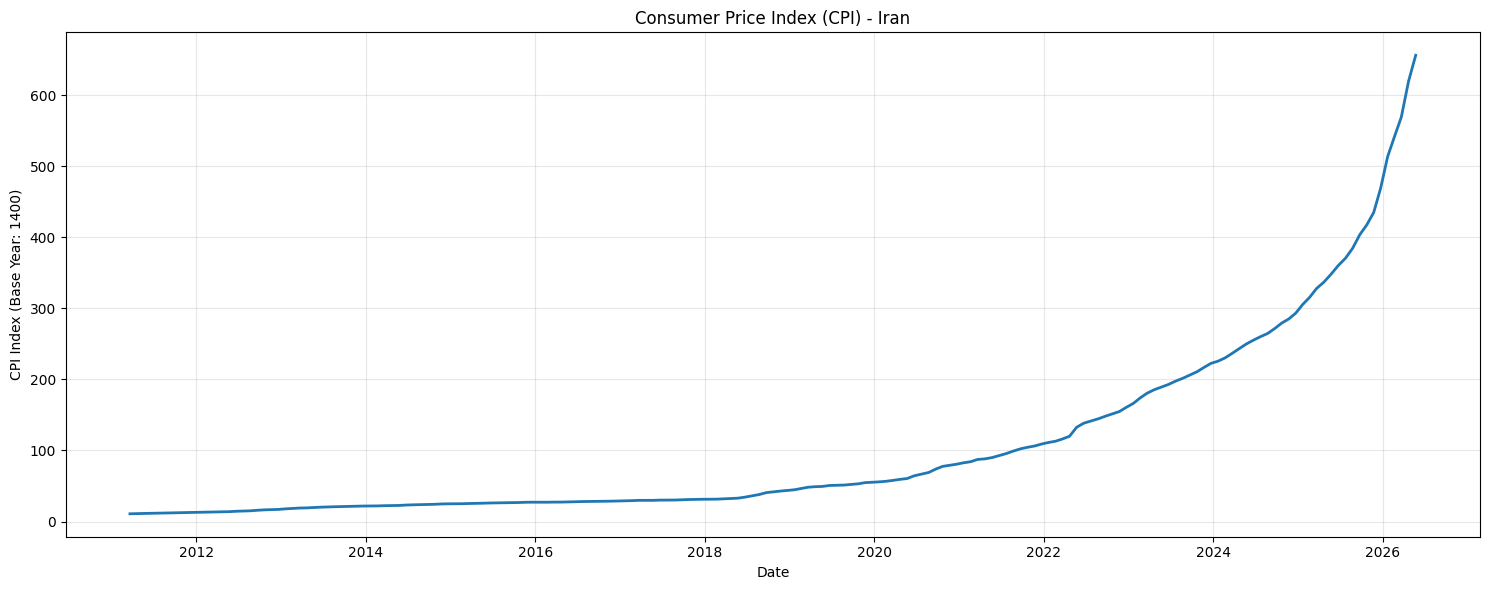

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    df_cpi['gregorian_date'],
    df_cpi['cpi_index'],
    linewidth=2
)

plt.title('Consumer Price Index (CPI) - Iran')
plt.xlabel('Date')
plt.ylabel('CPI Index (Base Year: 1400)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

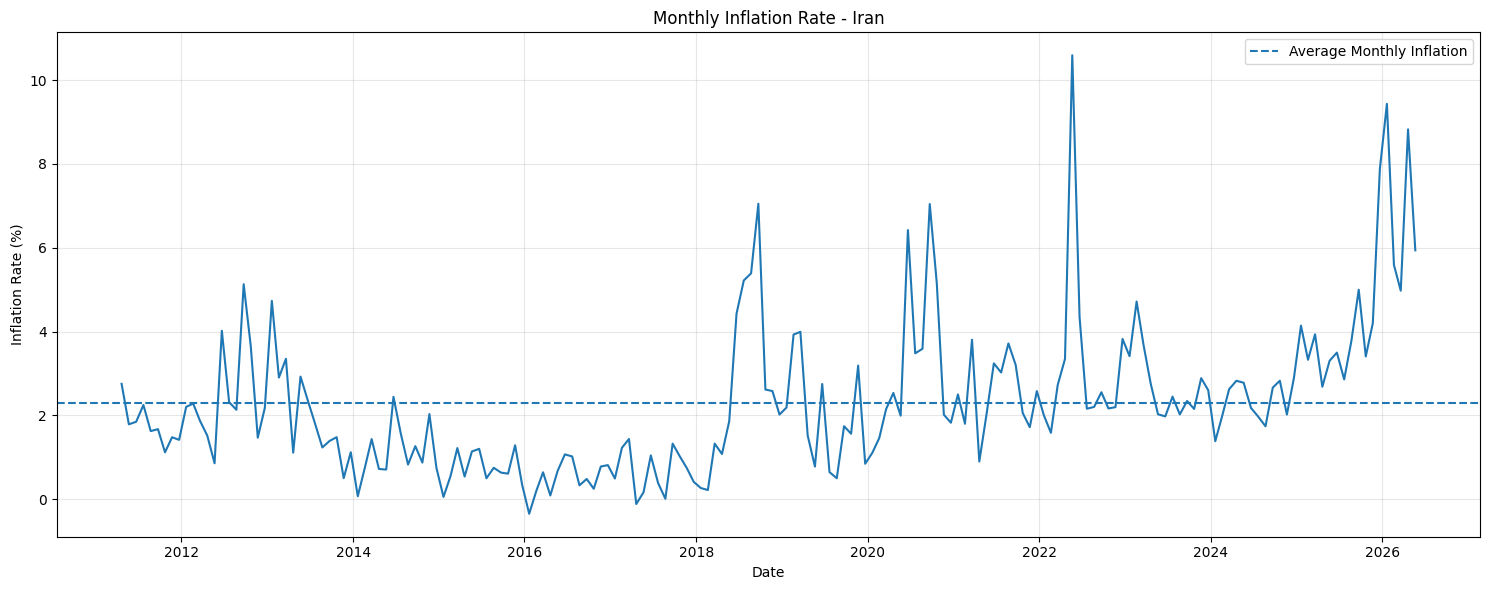

In [12]:
plt.figure(figsize=(15, 6))

plt.plot(
    df_cpi['gregorian_date'],
    df_cpi['inflation_mom'],
    linewidth=1.5
)

plt.axhline(
    y=df_cpi['inflation_mom'].mean(),
    linestyle='--',
    label='Average Monthly Inflation'
)

plt.title('Monthly Inflation Rate - Iran')
plt.xlabel('Date')
plt.ylabel('Inflation Rate (%)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
top_10_inflation = (
    df_cpi[
        ['period', 'gregorian_date', 'inflation_mom']
    ]
    .dropna(subset=['inflation_mom'])
    .sort_values(
        by='inflation_mom',
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

top_10_inflation

,period,gregorian_date,inflation_mom
0,1401-03,2022-05-22,10.591968
1,1404-11,2026-01-21,9.432659
2,1405-02,2026-04-21,8.825352
3,1404-10,2025-12-22,7.878815
4,1397-07,2018-09-23,7.050325
5,1399-07,2020-09-22,7.042948
6,1399-04,2020-06-21,6.422263
7,1405-03,2026-05-22,5.938838
8,1404-12,2026-02-20,5.588386
9,1397-06,2018-08-23,5.389664


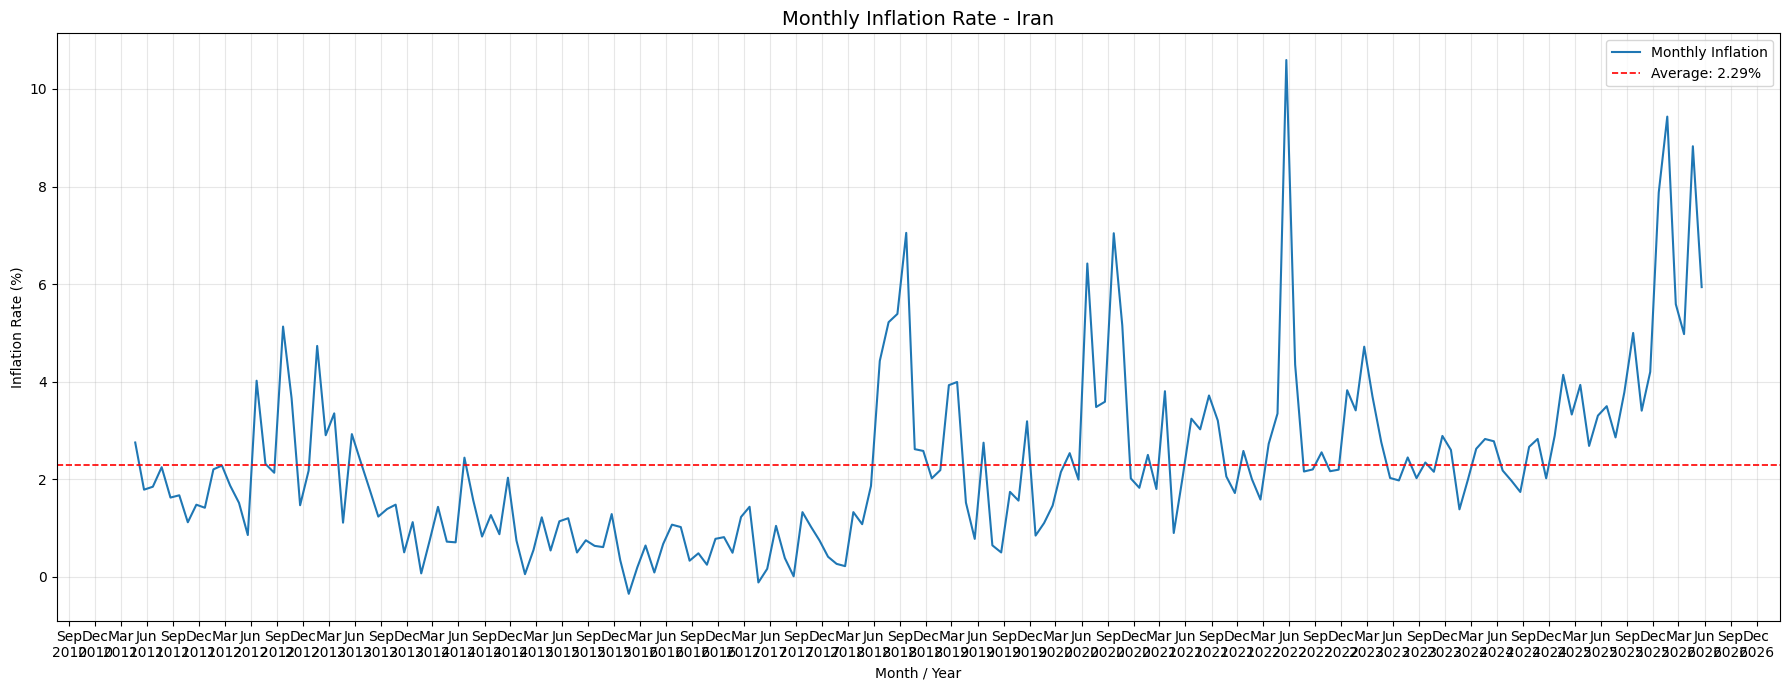

In [14]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(18, 7))

plt.plot(
    df_cpi['gregorian_date'],
    df_cpi['inflation_mom'],
    linewidth=1.5,
    label='Monthly Inflation'
)

# میانگین تورم ماهانه
avg_inflation = df_cpi['inflation_mom'].mean()

plt.axhline(
    y=avg_inflation,
    color='red',
    linestyle='--',
    linewidth=1.2,
    label=f'Average: {avg_inflation:.2f}%'
)

# نمایش نام اختصاری ماه‌های میلادی
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))

plt.title('Monthly Inflation Rate - Iran', fontsize=14)
plt.xlabel('Month / Year')
plt.ylabel('Inflation Rate (%)')

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
annual_mom = (
    df_cpi
    .groupby('year')['inflation_mom']
    .agg(['mean', 'median', 'max', 'min'])
    .round(2)
    .reset_index()
)

annual_mom.columns = [
    'year',
    'average_inflation',
    'median_inflation',
    'max_inflation',
    'min_inflation'
]

annual_mom

,year,average_inflation,median_inflation,max_inflation,min_inflation
0,1390,1.86,1.79,2.75,1.12
1,1391,2.73,2.25,5.13,0.86
2,1392,1.51,1.31,3.35,0.07
3,1393,1.10,0.85,2.44,0.06
4,1394,0.67,0.62,1.29,-0.35
5,1395,0.66,0.66,1.23,0.09
6,1396,0.58,0.40,1.44,-0.11
7,1397,3.31,2.60,7.05,1.08
8,1398,1.68,1.49,3.99,0.50
9,1399,3.38,2.52,7.04,1.80


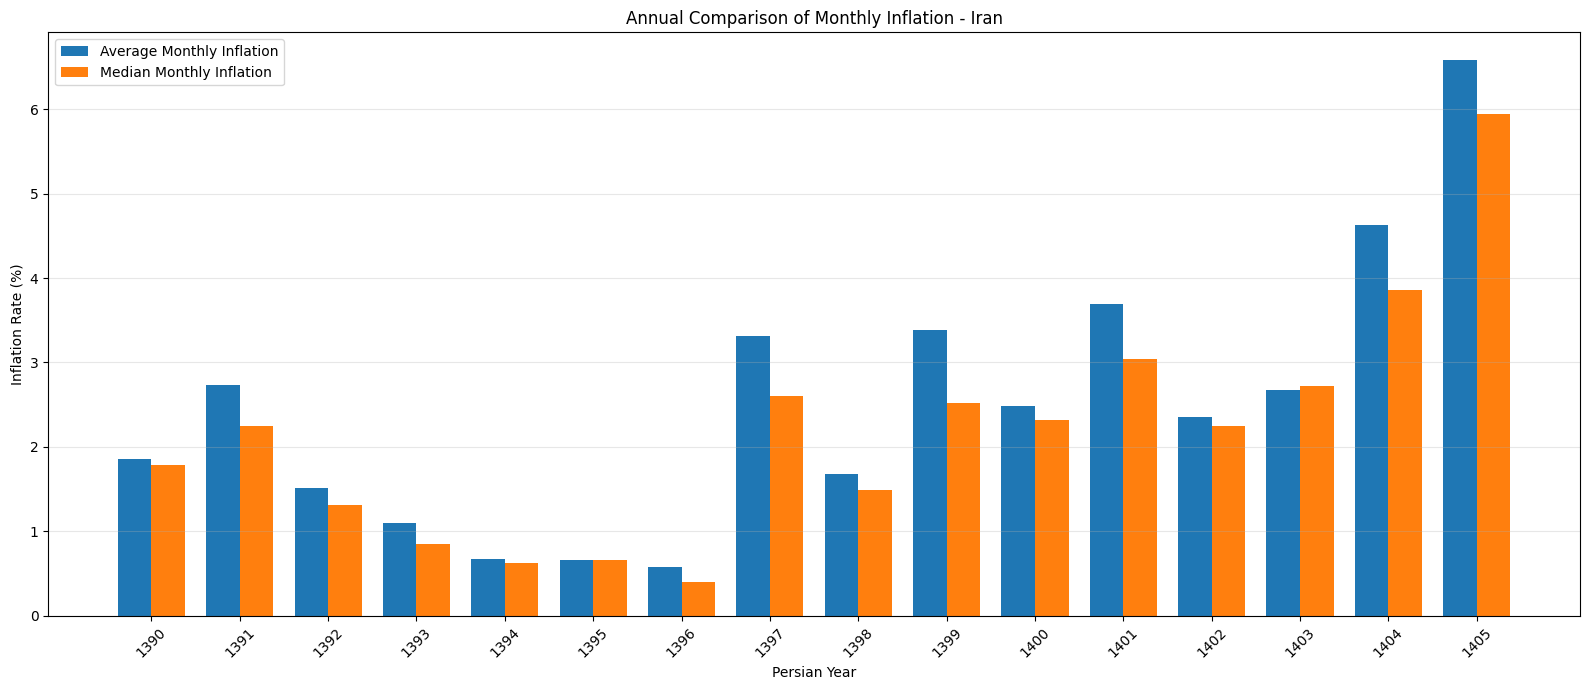

In [16]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(annual_mom))
width = 0.38

plt.figure(figsize=(16, 7))

plt.bar(
    x - width/2,
    annual_mom['average_inflation'],
    width,
    label='Average Monthly Inflation'
)

plt.bar(
    x + width/2,
    annual_mom['median_inflation'],
    width,
    label='Median Monthly Inflation'
)

plt.xticks(x, annual_mom['year'], rotation=45)

plt.title('Annual Comparison of Monthly Inflation - Iran')
plt.xlabel('Persian Year')
plt.ylabel('Inflation Rate (%)')

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

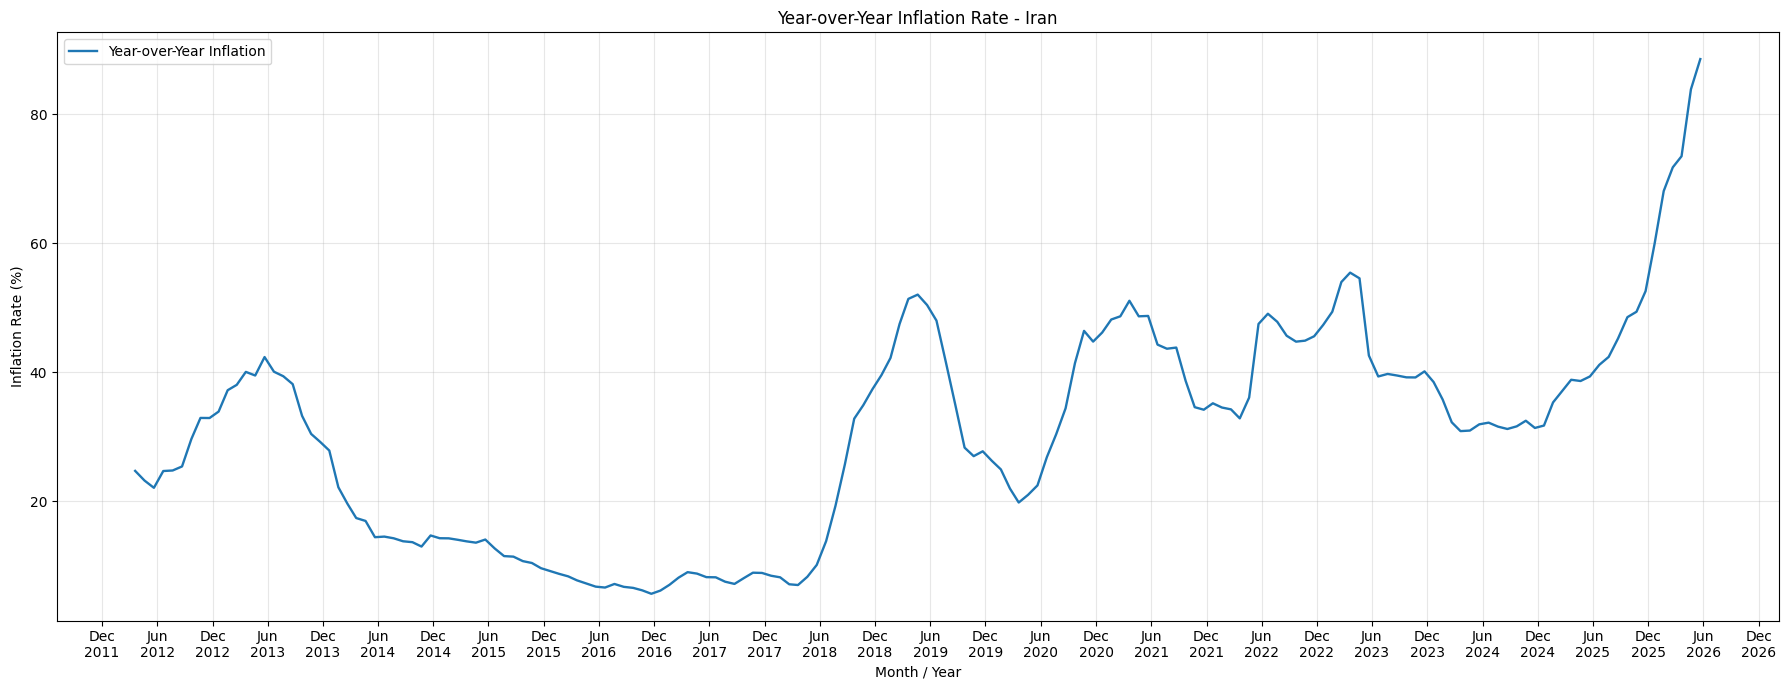

In [23]:
plt.figure(figsize=(18, 7))

plt.plot(
    df_cpi['gregorian_date'],
    df_cpi['inflation_yoy'],
    linewidth=1.7,
    label='Year-over-Year Inflation'
)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))

plt.title('Year-over-Year Inflation Rate - Iran')
plt.xlabel('Month / Year')
plt.ylabel('Inflation Rate (%)')

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

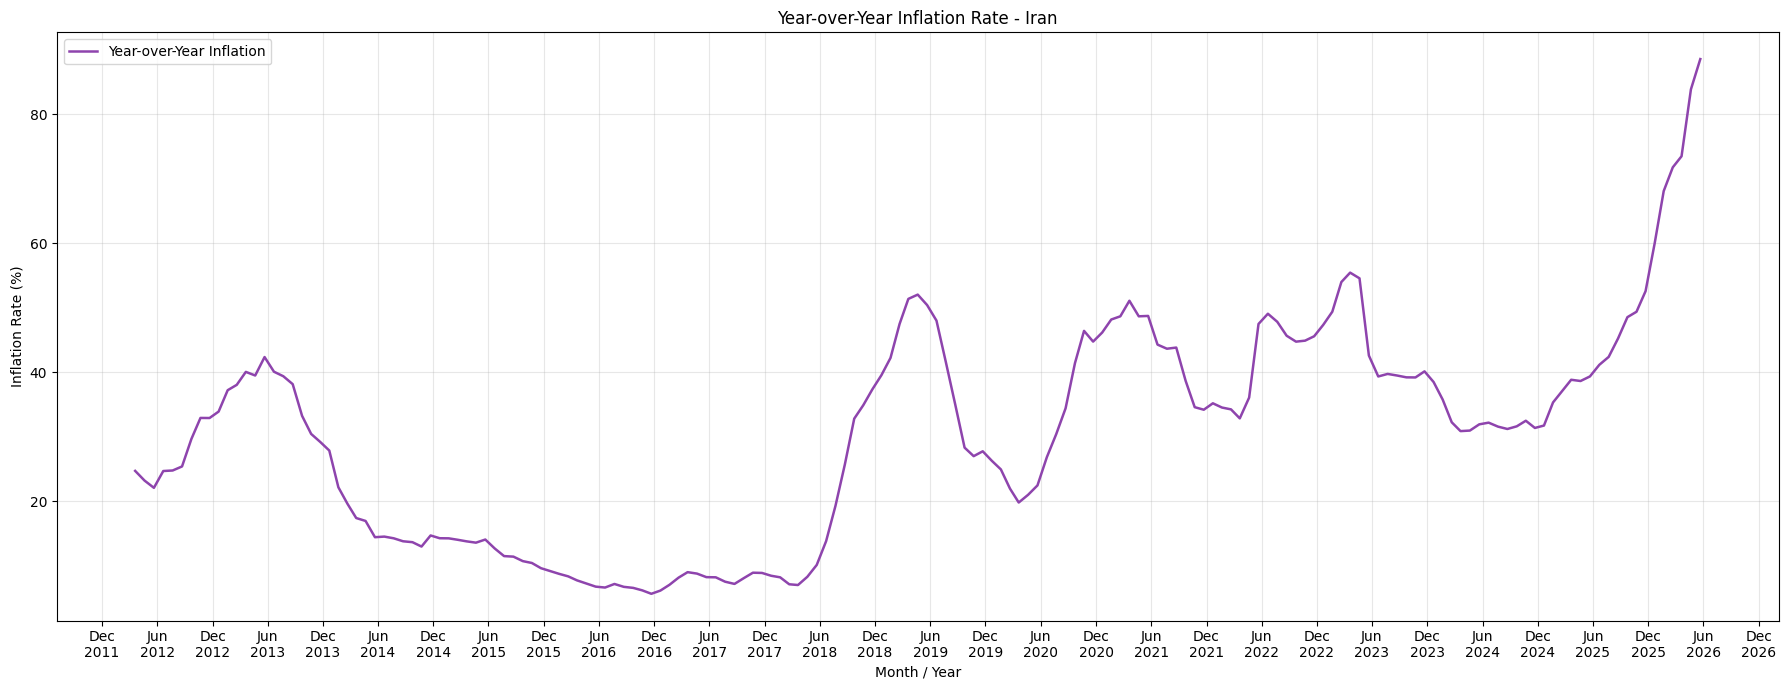

In [22]:
plt.figure(figsize=(18, 7))

plt.plot(
    df_cpi['gregorian_date'],
    df_cpi['inflation_yoy'],
    color='#8E44AD',
    linewidth=1.8,
    label='Year-over-Year Inflation'
)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(
    mdates.DateFormatter('%b\n%Y')
)

plt.title('Year-over-Year Inflation Rate - Iran')
plt.xlabel('Month / Year')
plt.ylabel('Inflation Rate (%)')

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
top_10_yoy = (
    df_cpi[
        ['period', 'gregorian_date', 'inflation_yoy']
    ]
    .dropna(subset=['inflation_yoy'])
    .sort_values(
        by='inflation_yoy',
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

top_10_yoy

,period,gregorian_date,inflation_yoy
0,1405-03,2026-05-22,88.580200
1,1405-02,2026-04-21,83.892085
2,1405-01,2026-03-21,73.515170
3,1404-12,2026-02-20,71.794934
4,1404-11,2026-01-21,68.117385
5,1404-10,2025-12-22,59.989597
6,1402-01,2023-03-21,55.469543
7,1402-02,2023-04-21,54.585176
8,1401-12,2023-02-20,54.013928
9,1404-09,2025-11-22,52.596445


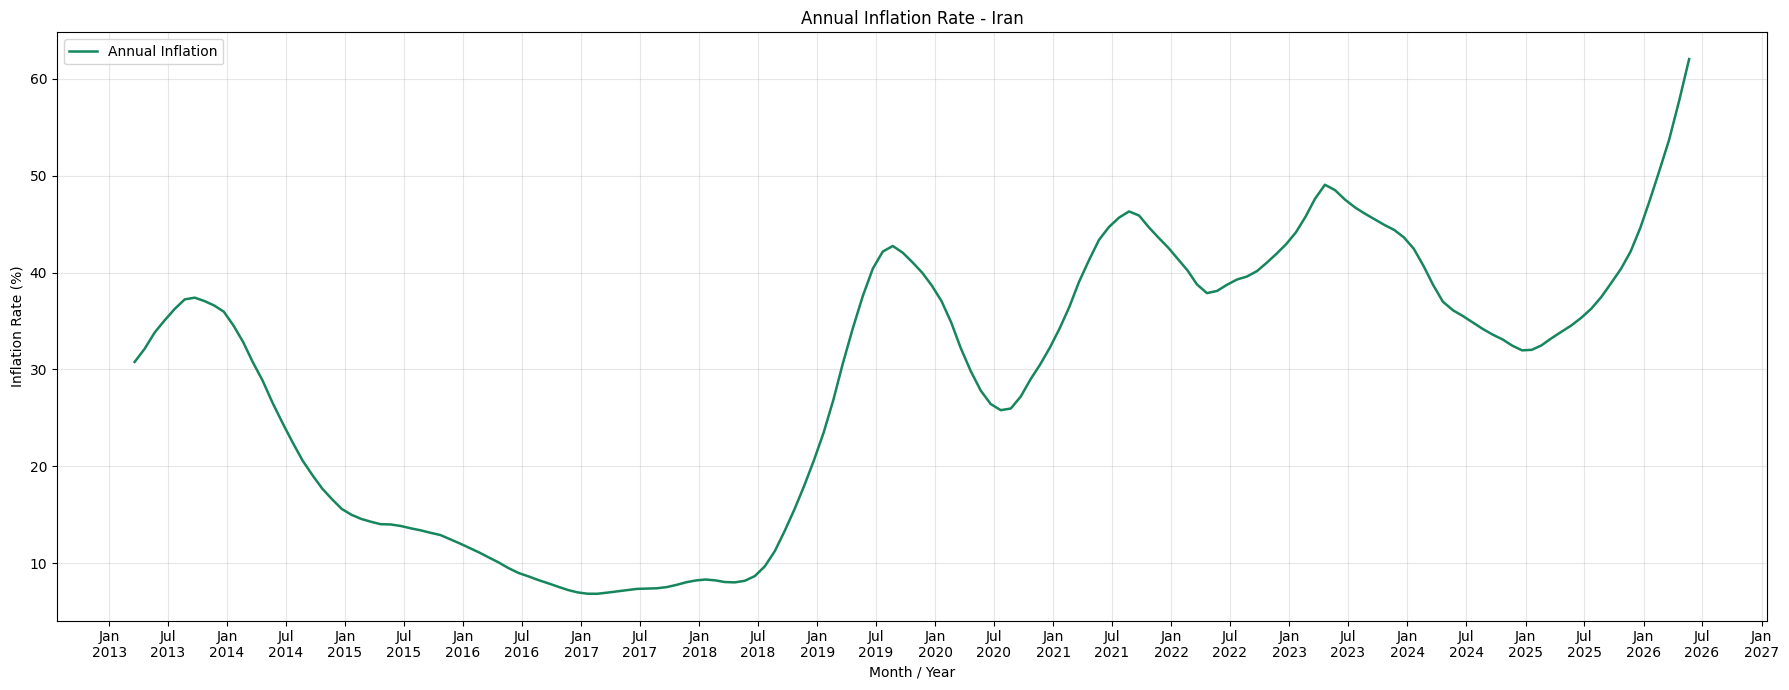

In [25]:
plt.figure(figsize=(18, 7))

plt.plot(
    df_cpi['gregorian_date'],
    df_cpi['inflation_annual'],
    color='#16865C',
    linewidth=1.8,
    label='Annual Inflation'
)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(
    mdates.DateFormatter('%b\n%Y')
)

plt.title('Annual Inflation Rate - Iran')
plt.xlabel('Month / Year')
plt.ylabel('Inflation Rate (%)')

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
top_annual = (
    df_cpi[
        ['period', 'gregorian_date', 'inflation_annual']
    ]
    .sort_values(
        by='inflation_annual',
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

top_annual

,period,gregorian_date,inflation_annual
0,1405-03,2026-05-22,62.022827
1,1405-02,2026-04-21,57.698993
2,1405-01,2026-03-21,53.686516
3,1404-12,2026-02-20,50.616097
4,1402-02,2023-04-21,49.056390
5,1402-03,2023-05-22,48.506994
6,1402-01,2023-03-21,47.586577
7,1404-11,2026-01-21,47.530447
8,1402-04,2023-06-22,47.528387
9,1402-05,2023-07-23,46.718971


In [27]:
annual_inflation_stats = (
    df_cpi
    .groupby('year')['inflation_annual']
    .agg(['mean', 'median', 'max', 'min', 'count'])
    .round(2)
    .reset_index()
)

annual_inflation_stats.columns = [
    'year',
    'average_inflation',
    'median_inflation',
    'max_inflation',
    'min_inflation',
    'month_count'
]

annual_inflation_stats

,year,average_inflation,median_inflation,max_inflation,min_inflation,month_count
0,1390,NaN,NaN,NaN,NaN,0
1,1391,NaN,NaN,NaN,NaN,0
2,1392,34.97,35.52,37.41,30.77,12
3,1393,21.02,19.82,30.79,14.58,12
4,1394,13.04,13.27,14.30,11.12,12
5,1395,8.30,8.09,10.62,6.86,12
6,1396,7.64,7.49,8.33,6.97,12
7,1397,14.32,12.32,26.85,8.03,12
8,1398,38.44,39.31,42.74,30.57,12
9,1399,29.81,29.41,36.43,25.80,12


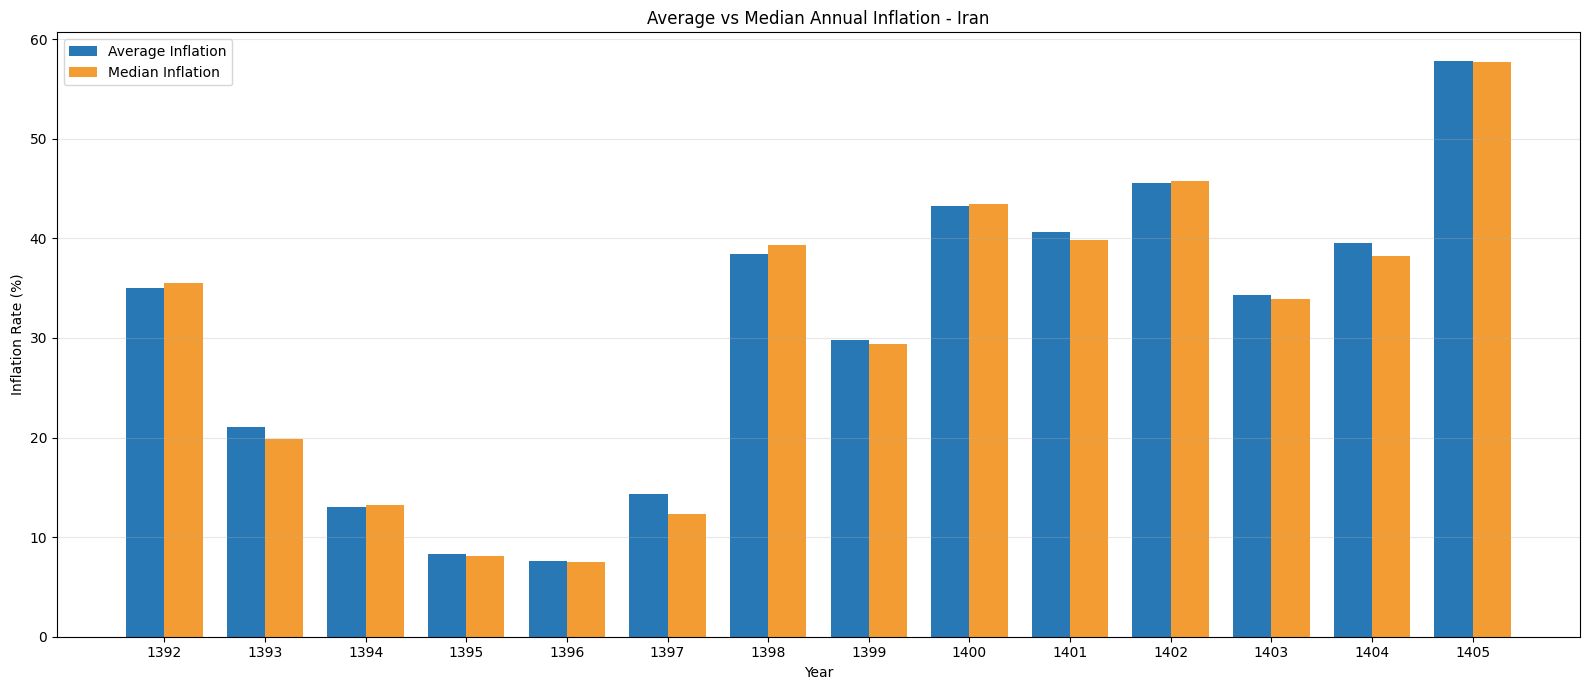

In [28]:
import numpy as np
import matplotlib.pyplot as plt

plot_data = annual_inflation_stats.dropna(
    subset=['average_inflation', 'median_inflation']
).copy()

x = np.arange(len(plot_data))
width = 0.38

plt.figure(figsize=(16, 7))

plt.bar(
    x - width/2,
    plot_data['average_inflation'],
    width,
    label='Average Inflation',
    color='#2878B5'
)

plt.bar(
    x + width/2,
    plot_data['median_inflation'],
    width,
    label='Median Inflation',
    color='#F39C34'
)

plt.xticks(x, plot_data['year'])

plt.title('Average vs Median Annual Inflation - Iran')
plt.xlabel('Year')
plt.ylabel('Inflation Rate (%)')

plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
annual_cpi = (
    df_cpi
    .groupby('year')['cpi_index']
    .agg(['mean', 'median', 'max', 'min'])
    .round(2)
    .reset_index()
)

annual_cpi.columns = [
    'year',
    'average_cpi',
    'median_cpi',
    'max_cpi',
    'min_cpi'
]

annual_cpi

,year,average_cpi,median_cpi,max_cpi,min_cpi
0,1390,12.07,12.12,13.29,10.86
1,1391,15.63,15.46,18.35,13.54
2,1392,20.76,20.97,21.96,18.97
3,1393,23.78,23.85,25.04,22.27
4,1394,26.43,26.50,27.18,25.35
5,1395,28.24,28.26,29.36,27.31
6,1396,30.57,30.43,31.46,29.75
7,1397,38.77,39.35,46.41,31.88
8,1398,52.28,51.77,56.61,48.26
9,1399,71.32,71.42,84.18,57.83


In [31]:
annual_cpi['annual_cpi_change'] = (
    annual_cpi['average_cpi']
    .pct_change() * 100
)

annual_cpi['gregorian_period'] = (
    df_cpi.groupby('year')['gregorian_date']
    .min()
    .dt.strftime('%Y-%m')
    .values
)

annual_cpi[
    ['year', 'gregorian_period',
     'average_cpi', 'annual_cpi_change']
].round(2)

,year,gregorian_period,average_cpi,annual_cpi_change
0,1390,2011-03,12.07,NaN
1,1391,2012-03,15.63,29.49
2,1392,2013-03,20.76,32.82
3,1393,2014-03,23.78,14.55
4,1394,2015-03,26.43,11.14
5,1395,2016-03,28.24,6.85
6,1396,2017-03,30.57,8.25
7,1397,2018-03,38.77,26.82
8,1398,2019-03,52.28,34.85
9,1399,2020-03,71.32,36.42


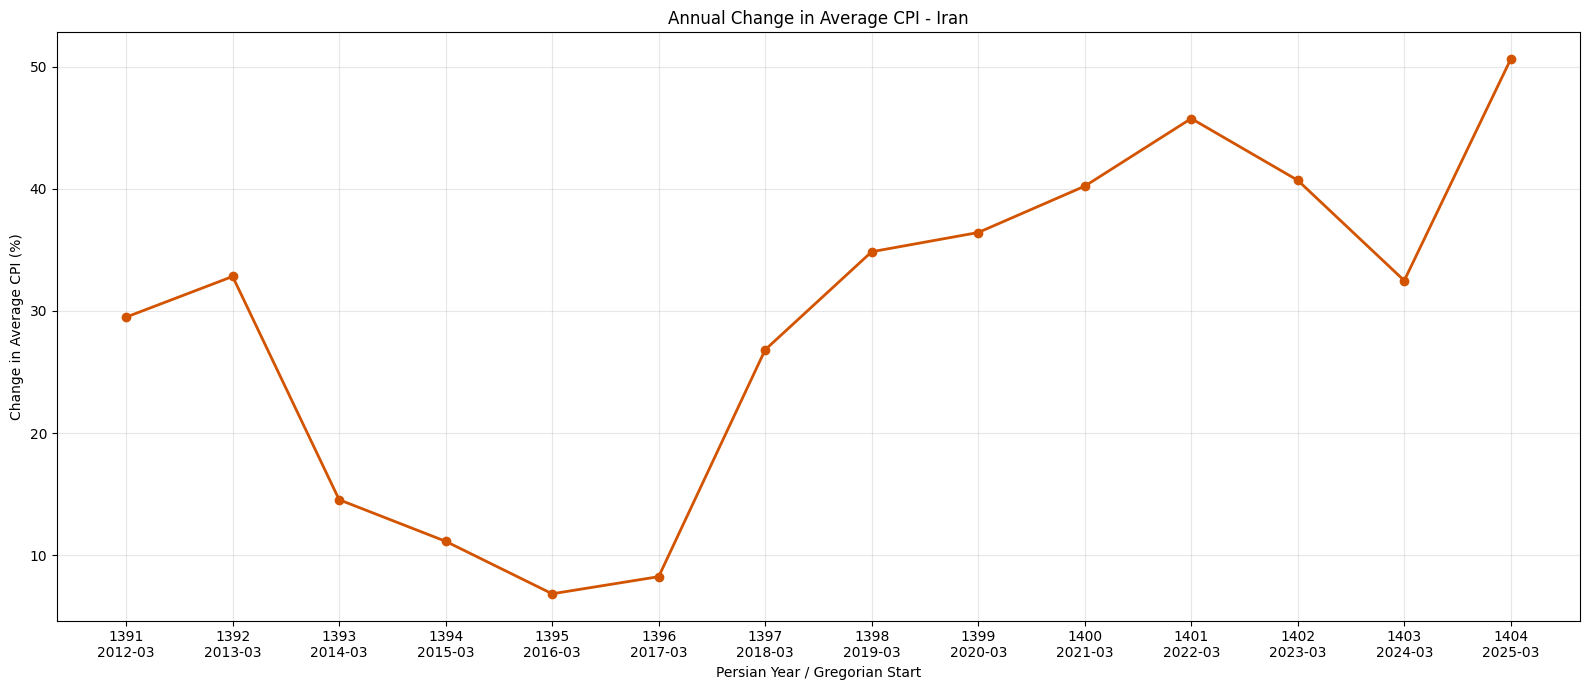

In [34]:
import matplotlib.pyplot as plt

plot_data = annual_cpi[
    (annual_cpi['year'] >= 1391) &
    (annual_cpi['year'] <= 1404)
].copy()

labels = (
    plot_data['year'].astype(str)
    + '\n'
    + plot_data['gregorian_period']
)

plt.figure(figsize=(16, 7))

plt.plot(
    plot_data['year'],
    plot_data['annual_cpi_change'],
    marker='o',
    color='#D35400',
    linewidth=2,
    markersize=6
)

plt.xticks(
    plot_data['year'],
    labels
)

plt.title('Annual Change in Average CPI - Iran')
plt.xlabel('Persian Year / Gregorian Start')
plt.ylabel('Change in Average CPI (%)')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
base_cpi = df_cpi[
    df_cpi['year'] == 1400
]['cpi_index'].mean()

df_cpi['cumulative_price_change'] = (
    (df_cpi['cpi_index'] / base_cpi) - 1
) * 100

df_cpi[
    ['period', 'gregorian_date',
     'cpi_index', 'cumulative_price_change']
].tail(10).round(2)

,period,gregorian_date,cpi_index,cumulative_price_change
173,1404-06,2025-08-23,384.56,284.56
174,1404-07,2025-09-23,403.78,303.78
175,1404-08,2025-10-23,417.54,317.54
176,1404-09,2025-11-22,435.08,335.08
177,1404-10,2025-12-22,469.36,369.36
178,1404-11,2026-01-21,513.64,413.64
179,1404-12,2026-02-20,542.34,442.34
180,1405-01,2026-03-21,569.33,469.33
181,1405-02,2026-04-21,619.57,519.57
182,1405-03,2026-05-22,656.37,556.37


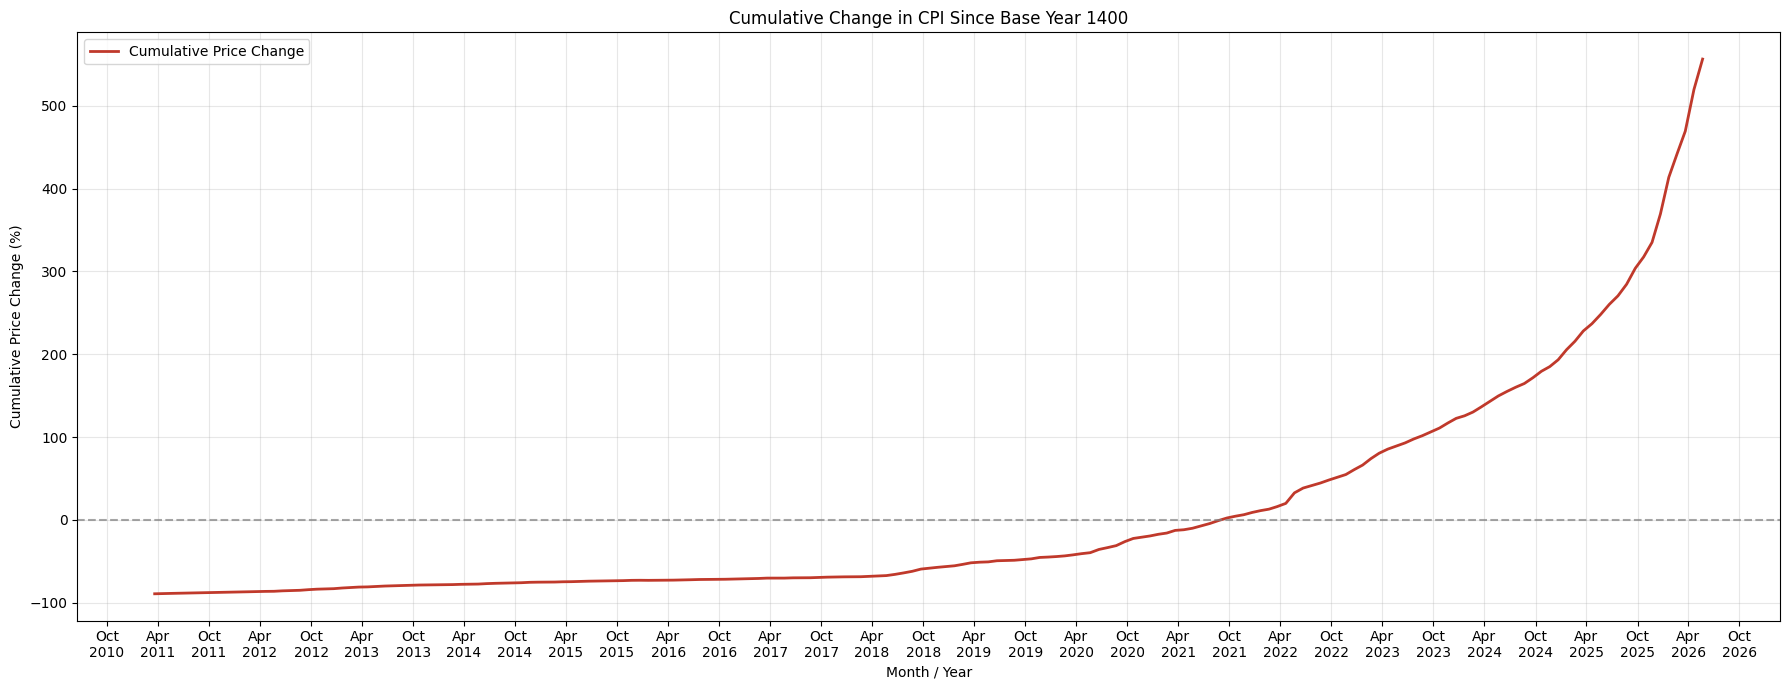

In [36]:
plt.figure(figsize=(18, 7))

plt.plot(
    df_cpi['gregorian_date'],
    df_cpi['cumulative_price_change'],
    color='#C0392B',
    linewidth=2,
    label='Cumulative Price Change'
)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(
    mdates.DateFormatter('%b\n%Y')
)

plt.axhline(
    y=0,
    color='gray',
    linestyle='--',
    alpha=0.7
)

plt.title('Cumulative Change in CPI Since Base Year 1400')
plt.xlabel('Month / Year')
plt.ylabel('Cumulative Price Change (%)')

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
cpi_quality = pd.DataFrame({
    'column': df_cpi.columns,
    'missing_values': df_cpi.isna().sum().values,
    'data_type': df_cpi.dtypes.astype(str).values,
    'unique_values': df_cpi.nunique().values
})

cpi_quality

,column,missing_values,data_type,unique_values
0,source_id,0,object,1
1,freq,0,object,1
2,period,0,object,183
3,year,0,int64,16
4,month,0,float64,12
5,base_year,0,int64,1
6,cpi_index,0,float64,183
7,inflation_annual,24,float64,159
8,inflation_yoy,12,float64,171
9,inflation_mom,1,float64,182


In [39]:
df_cpi.to_csv(
    'cpi_analysis_final.csv',
    index=False,
    encoding='utf-8-sig'
)